# ALBEDO: simulated and measured spectra

Counts only, no normalization: each spectrum is shown as it is, to compare shapes.

1. **Simulation**: choose the source and the number of photons, run it, optionally save the CSV.
2. **Measurement**: choose a measurement from `configs/measurements/`.
3. **Figures**: measured alone, simulated alone, and both side by side. Every figure
   setting (limits, scale) is a variable at the top of the figures section.

In [33]:
import matplotlib.pyplot as plt

from albedo import load_source, plotting, simulate
from albedo.experiment import ROOT, process_measurement

plotting.use_style()
RESULTS = ROOT / "results"


def short(n):
    """3e7 -> '3e7', 25000000 -> '2.5e7': compact number for file names."""
    mantissa, exponent = f"{n:.2e}".split("e")
    mantissa = mantissa.rstrip("0").rstrip(".")
    return f"{mantissa}e{int(exponent)}"

## 1. Simulation

In [34]:
SOURCE = "Ba-133"        # any file in data/sources: Cs-137, Ba-133, Mn-54, Y-88
SETUP = "csi_747E"       # any file in configs/setups
N_PHOTONS = 5e8          # about 1e6 photons per second
SEED = 1
BIN_WIDTH = 2.0          # keV
SMEAR = True             # apply the detector resolution (FWHM)
SAVE_CSV = True

In [ ]:
source = load_source(SOURCE)
print(source, "\n")

result = simulate(SETUP, source, N_PHOTONS, seed=SEED)
print(f"{result.n_histories:.3e} photons, {len(result.deposited)} detected "
      f"(efficiency {result.efficiency:.3e})")

sim_name = f"sim_{SOURCE}_{SETUP}_{short(N_PHOTONS)}photons_seed{SEED}_bin{BIN_WIDTH:g}keV"
if SAVE_CSV:
    path = result.to_csv(RESULTS / f"{sim_name}.csv", bin_width=BIN_WIDTH, seed=SEED)
    print("saved", path)

Ba-133  (KRI - 2015)
   E (keV)     I (%)  type
   30.6254   33.8000  XKa2 (Cs)
   30.9731   62.4000  XKa1 (Cs)
   35.0530   18.2400  XK'b1 (Cs)
   35.9003    4.4500  XK'b2 (Cs)
   53.1622    2.1400  g (Cs-133)
   79.6142    2.6300  g (Cs-133)
   80.9979   33.3100  g (Cs-133)
  160.6121    0.6380  g (Cs-133)
  223.2368    0.4500  g (Cs-133)
  276.3989    7.1300  g (Cs-133)
  302.8508   18.3100  g (Cs-133)
  356.0129   62.0500  g (Cs-133)
  383.8485    8.9400  g (Cs-133)
photons per decay: 2.5449 



## 2. Measurement

In [ ]:
MEASUREMENT = "cs137_2025-08-23"   # file in configs/measurements
SUBTRACT_BACKGROUND = True

In [ ]:
measured = process_measurement(MEASUREMENT)
exp_counts = measured.net if SUBTRACT_BACKGROUND else measured.counts
cal = measured.calibration
print(f"{MEASUREMENT}: {measured.source}, live time {measured.live_time:.0f} s, "
      f"{exp_counts.sum():.0f} counts")
print(f"calibration E = {cal.a0:.3f} + {cal.a1:.5f} * channel (keV)")

cs137_2025-08-23: Cs-137, live time 3600 s, 62459 counts
calibration E = 2.986 + 1.07216 * channel (keV)


## 3. Figures

In [ ]:
XLIM = (0, 800)          # keV
YLIM_EXP = None          # e.g. (0, 700); None = automatic
YLIM_SIM = None
LOG = False
SAVE_FIGURES = False     # write to figures/

sim_energy, sim_counts = result.spectrum(BIN_WIDTH, XLIM[1], smear=SMEAR, seed=SEED)
exp_label = "net counts" if SUBTRACT_BACKGROUND else "counts"


def style_axis(ax, ylim):
    ax.set_xlim(*XLIM)
    if LOG:
        ax.set_yscale("log")
    if ylim is not None:
        ax.set_ylim(*ylim)
    elif not LOG:
        ax.set_ylim(bottom=0)
    ax.set_xlabel(r"$E\,(\mathrm{keV})$")

### Measured

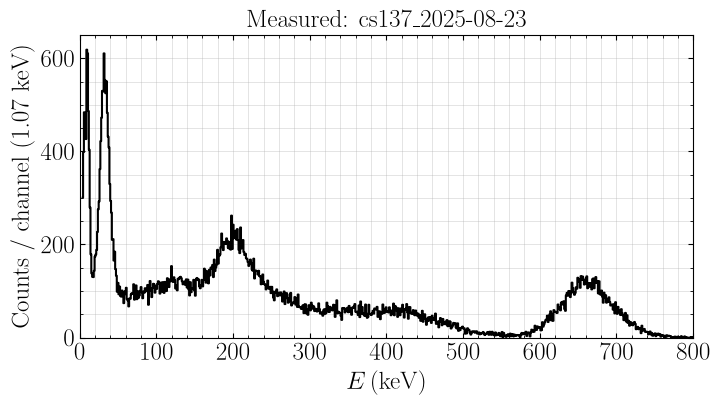

In [ ]:
fig, ax = plt.subplots(figsize=plotting.cm(18, 10), layout="constrained")
ax.step(measured.energy, exp_counts, where="mid", color="black")
ax.set_title(f"Measured: {MEASUREMENT}")
ax.set_ylabel(f"Counts / channel ({cal.a1:.2f} keV)")
style_axis(ax, YLIM_EXP)
if SAVE_FIGURES:
    plotting.save(fig, f"exp_{MEASUREMENT}")
plt.show()

### Simulated

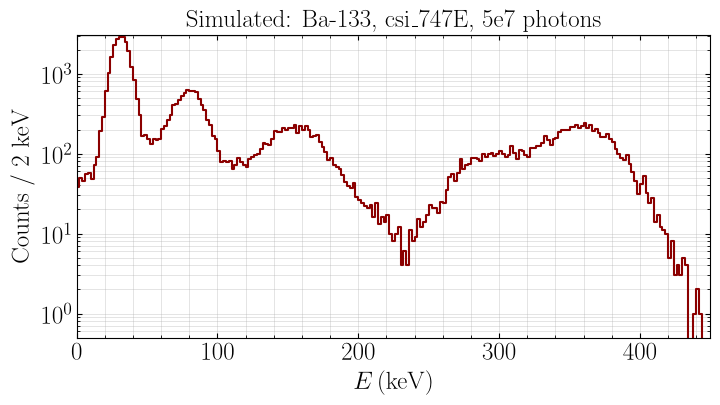

In [ ]:
fig, ax = plt.subplots(figsize=plotting.cm(18, 10), layout="constrained")
ax.step(sim_energy, sim_counts, where="mid", color=plotting.COLORS["red"])
ax.set_title(f"Simulated: {SOURCE}, {SETUP}, {short(N_PHOTONS)} photons")
ax.set_ylabel(f"Counts / {BIN_WIDTH:g} keV")
style_axis(ax, YLIM_SIM)
ax.set_xlim(0, 450)          
ax.set_yscale("log")
ax.set_ylim(bottom=0.5) 
if SAVE_FIGURES:
    plotting.save(fig, sim_name)
plt.show()

### Side by side

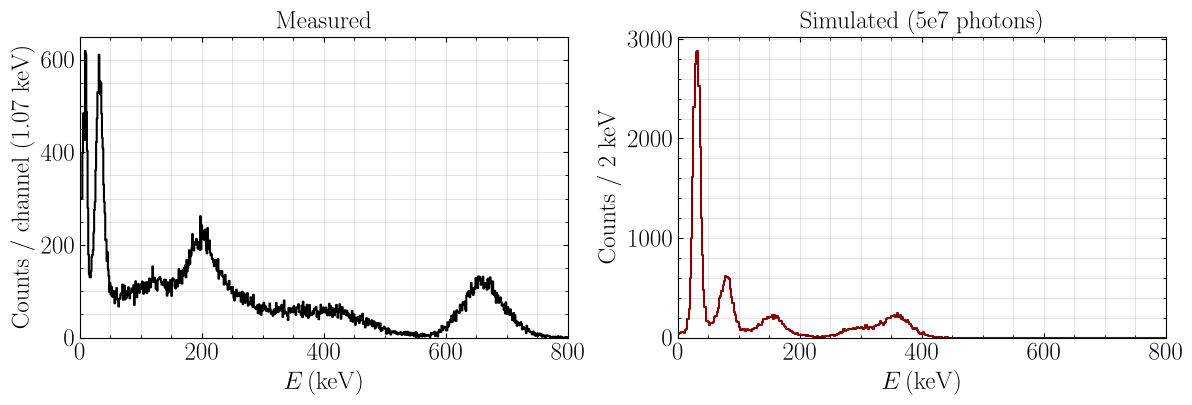

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=plotting.cm(30, 10), layout="constrained")

ax1.step(measured.energy, exp_counts, where="mid", color="black")
ax1.set_title("Measured")
ax1.set_ylabel(f"Counts / channel ({cal.a1:.2f} keV)")
style_axis(ax1, YLIM_EXP)

ax2.step(sim_energy, sim_counts, where="mid", color=plotting.COLORS["red"])
ax2.set_title(f"Simulated ({short(N_PHOTONS)} photons)")
ax2.set_ylabel(f"Counts / {BIN_WIDTH:g} keV")
style_axis(ax2, YLIM_SIM)

if SAVE_FIGURES:
    plotting.save(fig, f"side_{MEASUREMENT}_{sim_name}")
plt.show()